<a href="https://colab.research.google.com/github/noeliacualina/Procesamiento_digital_imagenes/blob/TrabajoPractico_2/TP2/TP2_Integrador_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**UGR**

# Trabajo Práctico N°2 — Integrador Final
## Procesamiento Digital de Imágenes (V.CLCD2.10.1)

**Integrantes (hasta 4):**
- Martinez Gisela
- Cualina Noelia
- Carabajal Javier
- Carabajal Leonardo
---

### Cómo usar esta plantilla
- Cada sección corresponde a un paso del enunciado. **Completen los `# TODO`** de cada función.
- En cada sección hay una celda **"Decisiones y observaciones"**: ahí va la documentación (parte del Informe).
- El notebook debe **correr de arriba a abajo sin errores** antes de entregar (Entorno → Reiniciar y ejecutar todo).
- Muestren siempre la imagen **antes y después** de cada técnica.
- La entrega final = este notebook ejecutado + (opcional) export a PDF para subir a la plataforma.


**Objetivo**

Extender el sistema de detección y clasificación de formas geométricas del TP1 para que funcione sobre imágenes reales (con ruido, distintas condiciones de iluminación, perspectiva y color), integrando las técnicas vistas en toda la materia, utilizando OpenCV en Google Colab.


**Descripción**
Partiendo del clasificador desarrollado en el TP1, deberán construir un sistema completo que adquiera, mejore, restaure, transforme, segmente y analice imágenes, clasificando las formas por su geometría y por su color. Pueden presentarlo en grupos de hasta 4 alumnos.


**Pasos del proyecto**

Punto de partida (TP1)

•  Reutilizar el clasificador de formas del TP1 como función base y usarlo como línea de comparación.
Adquisición y formatos

•  Armar un conjunto propio de al menos 8 imágenes con formas, en condiciones variadas.
•  Comparar una misma imagen guardada en BMP, PNG y JPEG (tamaño y calidad).

Mejora y restauración

•  Mostrar el efecto de la cuantización de niveles de gris y del submuestreo (aliasing).
•  Mejorar el contraste con ajuste lineal, corrección gamma y ecualización de histograma.
•  Agregar ruido (sal y pimienta y gaussiano) y comparar filtros de media, gaussiano y mediana.

Transformaciones y morfología

•  Aplicar rotación, escalado, traslación y corregir la perspectiva de una figura (homografía).
•  Aplicar erosión, dilatación, apertura y cierre con distintos elementos estructurantes.

Detección de bordes y segmentación

•  Comparar los operadores Sobel, Prewitt y Laplaciano (y Canny).
•  Segmentar las figuras del fondo (umbralización / Otsu) y contar cuántas hay.

Color

•  Separar los canales RGB y convertir a HSV.
•  Segmentar las figuras por color en HSV y aplicar un mapa de pseudocolor.

Sistema integrador

•  Encadenar las técnicas anteriores en un único pipeline que reciba una imagen real y devuelva cada forma detectada con su tipo, su color y el conteo total.
•  Comparar la robustez del sistema final contra el clasificador del TP1.


**Entregables**

1) Código fuente: notebook de Google Colab ejecutable y comentado.
2) Informe técnico: documento (puede ser el mismo notebook con celdas de texto, o un archivo aparte en PDF) donde expliquen TÉCNICAMENTE cómo resolvieron el trabajo, al igual que en el TP1. Para cada etapa deben indicar:
•  Qué técnica/función de OpenCV usaron y para qué.
•  Por qué tomaron esa decisión y qué parámetros eligieron (umbral, gamma, kernels, rangos HSV, filtros, etc.).
•  Qué resultado obtuvieron, mostrando la imagen antes y después.
El informe cierra con una comparación de la robustez del sistema integrador frente al clasificador del TP1 y con las conclusiones (qué aprendieron, limitaciones y posibles mejoras).
3) Defensa oral del trabajo en grupo: todos los integrantes deben poder explicar cualquier parte.


## Carga de Imagenes

In [1]:
!unzip -o imagenes_TP2.zip
!ls imagenes

Archive:  imagenes_TP2.zip
   creating: imagenes/
  inflating: imagenes/06_naranja.jpg  
  inflating: imagenes/04_cubo_arriba.jpg  
  inflating: imagenes/03_granito_5objetos.jpg  
  inflating: imagenes/08_cubo_sombra.jpg  
  inflating: imagenes/07_pelota_servilleta.jpg  
  inflating: imagenes/10_poca_luz.jpg  
  inflating: imagenes/09_cubo_inclinado.jpg  
  inflating: imagenes/05_pelota_blanca.jpg  
  inflating: imagenes/01_cesped_6objetos.jpg  
  inflating: imagenes/02_cesped_5objetos.jpg  
01_cesped_6objetos.jpg	 05_pelota_blanca.jpg	   09_cubo_inclinado.jpg
02_cesped_5objetos.jpg	 06_naranja.jpg		   10_poca_luz.jpg
03_granito_5objetos.jpg  07_pelota_servilleta.jpg
04_cubo_arriba.jpg	 08_cubo_sombra.jpg


## 0. Configuración e importación de librerías

In [2]:
import cv2
import numpy as np
import math
import os
import matplotlib.pyplot as plt
import subprocess   # Para traer TP1
import nbformat     # Para leer archivos

def mostrar(imagenes, titulos=None, cols=3, cmap=None):
    """Muestra una o varias imágenes en una grilla.

    Args:
        imagenes: imagen única (ndarray) o lista de imágenes.
        titulos:  título o lista de títulos (opcional).
        cols:     columnas de la grilla.
        cmap:     'gray' para imágenes en escala de grises; None para color.
    """
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    if titulos is None:
        titulos = [""] * len(imagenes)
    elif not isinstance(titulos, (list, tuple)):
        titulos = [titulos]

    n = len(imagenes)
    filas = math.ceil(n / cols)
    plt.figure(figsize=(cols * 4, filas * 4))
    for i, img in enumerate(imagenes):
        plt.subplot(filas, cols, i + 1)
        # Si es color (BGR de OpenCV) lo paso a RGB para matplotlib
        if cmap is None and img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            #plt.imshow(img, cmap=cmap or 'gray')
            plt.imshow(img, cmap=cmap or 'gray', vmin=0, vmax=255)
        plt.title(titulos[i] if i < len(titulos) else "")
        plt.axis('off')
    plt.tight_layout()
    plt.show()


### 1. Clasificador del TP1

In [3]:
# Trae el clasificador del TP1 desde GitHub ----
REPO_TP1 = "https://github.com/noeliacualina/Procesamiento_digital_imagenes.git"
CARPETA_TP1 = "Procesamiento_digital_imagenes"

if not os.path.isdir(CARPETA_TP1):
    subprocess.run(["git", "clone", "-q", "-b", "TrabajoPractico_1",
                    REPO_TP1, CARPETA_TP1], check=True)

nb_tp1 = nbformat.read(f"{CARPETA_TP1}/TrabajoPractico_N1.ipynb", as_version=4)
for celda in nb_tp1.cells:
    if celda.cell_type == "code" and "def clasificar_forma(" in celda.source:
        espacio = {"cv2": cv2, "np": np}
        exec(celda.source, espacio)
        clasificar_forma_tp1 = espacio["clasificar_forma"]


# Funcion Clasificar
def clasificar_formas(img_bgr):
    """Clasificador del TP1: detecta y clasifica formas geométricas en una imagen.

    Reutilizar acá la lógica del TP1 (gris -> suavizado -> umbral -> contornos ->
    approxPolyDP por número de vértices + relación de aspecto).

    Args:
        img_bgr: imagen de entrada en BGR.
    Returns:
        (img_resultado, detecciones)
        img_resultado: copia de la imagen con las formas rotuladas.
        detecciones:   lista de dicts, p.ej. {"tipo": "Cuadrado", "contorno": cnt}

    """
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suave, 50, 150)
    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)

    alto, ancho = gris.shape
    area_minima = alto * ancho * 0.0001
    escala = max(0.6, min(alto, ancho) / 600)
    resultado = img_bgr.copy()
    detecciones = []

    for contorno in contornos:
        if cv2.contourArea(contorno) <= area_minima:
            continue
        perimetro = cv2.arcLength(contorno, True)
        aproximacion = cv2.approxPolyDP(contorno, 0.02 * perimetro, True)
        tipo = clasificar_forma_tp1(contorno, aproximacion)
        detecciones.append({"tipo": tipo, "contorno": contorno})
        if tipo == "No identificada":
            continue
        cv2.drawContours(resultado, [aproximacion], -1, (0, 255, 0), max(2, int(escala * 3)))
        m = cv2.moments(aproximacion)
        if m["m00"] != 0:
            cx, cy = int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])
            cv2.putText(resultado, tipo, (cx - 40, cy), cv2.FONT_HERSHEY_SIMPLEX,
                        escala, (0, 0, 255), max(2, int(escala * 2)))

    return resultado, detecciones

Contornos analizados: 15
['No identificada', 'Rectangulo', 'No identificada', 'Rectangulo', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'Circulo', 'No identificada', 'No identificada']


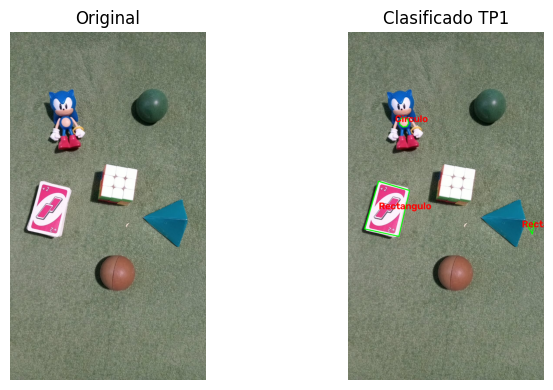

In [4]:
# --- Ejemplo de uso (descomentar y adaptar) ---
img = cv2.imread("imagenes/01_cesped_6objetos.jpg")
resultado, detecciones = clasificar_formas(img)
print(f"Contornos analizados: {len(detecciones)}")
print([d["tipo"] for d in detecciones])
mostrar([img, resultado], ["Original", "Clasificado TP1"], cols=2)

## 2. Adquisición y formatos

- Armar un conjunto propio de **al menos 8 imágenes** con formas, en condiciones variadas.
- Comparar una misma imagen guardada en **BMP, PNG y JPEG** (tamaño y calidad).


In [5]:
# Mide cuánto se parece una imagen a otra, y se usa para comparar calidad
def psnr(a, b):
    """PSNR en dB entre dos imágenes de 8 bits (misma fórmula que cv2.PSNR)."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)


def cargar_imagenes(rutas):
    """Carga una lista de imágenes desde disco (BGR)."""
    imagenes = {}
    for ruta in rutas:
        img = cv2.imread(ruta)
        if img is None:
            print(f"No se pudo leer: {ruta}")
            continue
        imagenes[os.path.basename(ruta)] = img
    return imagenes


def comparar_formatos(img_bgr, nombre_base="muestra"):
    """Guarda la misma imagen en BMP, PNG y JPEG y compara tamaño en disco y calidad.

    Pista: cv2.imwrite(f"{nombre_base}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
           os.path.getsize(ruta) para el tamaño en bytes.
    """
    rutas = {"BMP": f"{nombre_base}.bmp",
             "PNG": f"{nombre_base}.png",
             "JPEG": f"{nombre_base}.jpg"}

    cv2.imwrite(rutas["BMP"], img_bgr)
    cv2.imwrite(rutas["PNG"], img_bgr)
    cv2.imwrite(rutas["JPEG"], img_bgr, [cv2.IMWRITE_JPEG_QUALITY, 90])

    tam_bmp = os.path.getsize(rutas["BMP"])
    tabla = {}
    print(f"{'Formato':<8}{'Tamaño (KB)':>14}{'% del BMP':>12}{'PSNR (dB)':>16}")
    for formato, ruta in rutas.items():
        tam = os.path.getsize(ruta)
        leida = cv2.imread(ruta)
        if np.array_equal(leida, img_bgr):
            calidad = "sin pérdida"
        else:
            calidad = f"{psnr(img_bgr, leida):.2f}"
        tabla[formato] = {"kb": tam / 1024, "porcentaje": 100 * tam / tam_bmp, "psnr": calidad}
        print(f"{formato:<8}{tam / 1024:>14.2f}{100 * tam / tam_bmp:>12.2f}{calidad:>16}")
    return tabla

Imágenes cargadas: 10


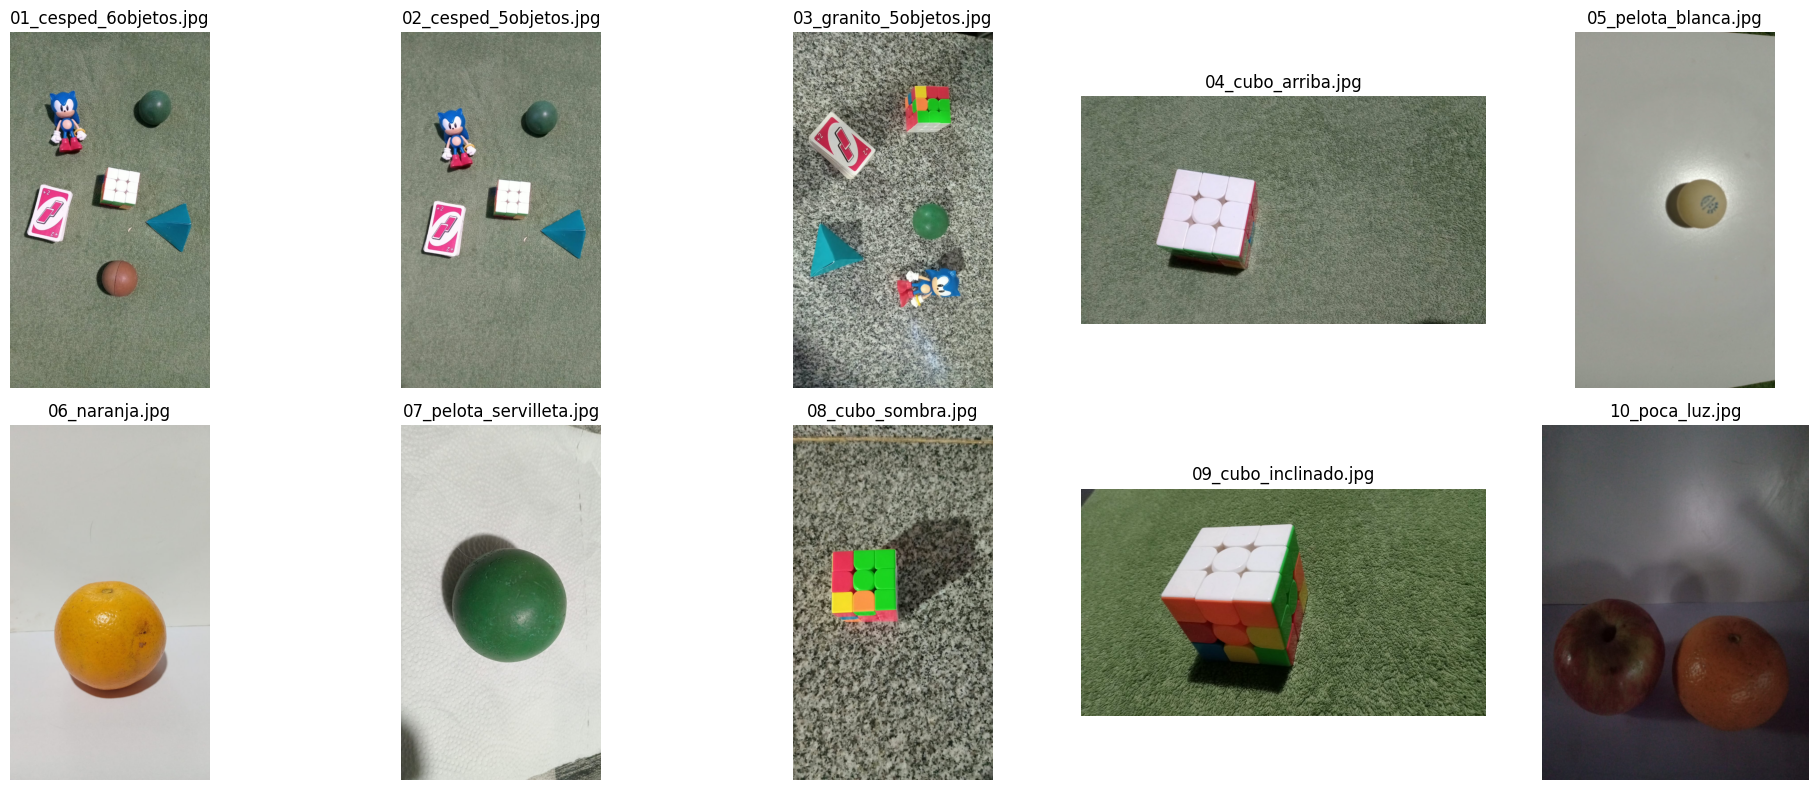

Formato    Tamaño (KB)   % del BMP       PSNR (dB)
BMP            4218.80      100.00     sin pérdida
PNG            3162.07       74.95     sin pérdida
JPEG            490.89       11.64           44.73


In [6]:
rutas = sorted(["imagenes/" + f for f in os.listdir("imagenes")
                if f.lower().endswith((".jpg", ".jpeg", ".png"))])
imgs = cargar_imagenes(rutas)
print(f"Imágenes cargadas: {len(imgs)}")
mostrar(list(imgs.values()), list(imgs.keys()), cols=5)

tabla = comparar_formatos(imgs["01_cesped_6objetos.jpg"], nombre_base="muestra")

**Decisiones y observaciones:**

Se comparó la misma imagen (`01_cesped_6objetos.jpg`, 1600 × 900 px) guardada en BMP, PNG y JPEG con `cv2.imwrite`. El JPEG se guardó con `cv2.IMWRITE_JPEG_QUALITY = 90`. El tamaño en disco se midió con `os.path.getsize` y la calidad con `cv2.PSNR`.

| Formato | Tamaño (KB) | % del BMP | Calidad |
|---|---|---|---|
| BMP | 4218,80 | 100,00 | sin pérdida |
| PNG | 3162,07 | 74,95 | sin pérdida |
| JPEG (calidad 90) | 490,89 | 11,64 | PSNR 44,73 dB |

1. **Qué pesa más:** el BMP, porque guarda cada píxel sin comprimir: 1600 × 900 × 3 bytes = 4.320.000 bytes, unos 4218,75 KB.
2. **PNG:** comprime sin perder datos (al leerlo es idéntico al original), pero en esta foto solo ahorra 25,05 %, porque la textura del césped se comprime poco.
3. **JPEG:** es el más liviano (8,59 veces menos que el BMP), pero **pierde información**. Con calidad 90 la diferencia es chica: 44,73 dB, y por encima de 40 dB casi no se nota a simple vista.
4. **Por qué pierde calidad:** JPEG descarta detalles finos que el ojo percibe poco (transformada y cuantización de coeficientes). Eso lo achica, pero no se puede recuperar el original.
5. **Decisión:** se trabaja con imágenes sin pérdida (PNG). JPEG se usa solo para guardar o enviar, porque si se re-guarda varias veces la calidad sigue bajando.

*Nota: la comparación se hizo con una sola imagen; con una imagen lisa  PNG se comprimiría mucho más.*

## 3. Mejora y restauración

- Cuantización de niveles de gris y submuestreo (**aliasing**).
- Contraste: ajuste lineal, **corrección gamma** y **ecualización de histograma**.
- Ruido (**sal y pimienta** y **gaussiano**) y comparación de filtros media / gaussiano / mediana.


In [7]:
def cuantizar(img_gray, niveles):
    """Reduce la imagen a 'niveles' de gris.

    Pista: paso = 256 // niveles; (img // paso) * paso
    """
    paso = 256 // niveles
    return ((img_gray // paso) * paso).astype(np.uint8)


def submuestrear(img, factor):
    """Reduce y vuelve a ampliar para evidenciar aliasing.

    Pista: cv2.resize hacia abajo y luego hacia arriba con INTER_NEAREST.
    """
    alto, ancho = img.shape[:2]
    chica = cv2.resize(img, (int(ancho * factor), int(alto * factor)),
    interpolation=cv2.INTER_NEAREST)
    return cv2.resize(chica, (ancho, alto), interpolation=cv2.INTER_NEAREST)



def ajuste_lineal(img, alpha=1.5, beta=0):
    """Contraste/brillo lineal. Pista: cv2.convertScaleAbs(img, alpha=alpha, beta=beta)."""
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def correccion_gamma(img, gamma=1.0):
    """Corrección gamma usando una LUT.

    Pista: tabla = ((np.arange(256)/255.0) ** gamma) * 255 -> cv2.LUT(img, tabla.astype('uint8'))
    """
    tabla = ((np.arange(256) / 255.0) ** gamma) * 255
    return cv2.LUT(img, tabla.astype("uint8"))


def ecualizar(img_gray):
    """Ecualización de histograma. Pista: cv2.equalizeHist (o CLAHE)."""
    return cv2.equalizeHist(img_gray)


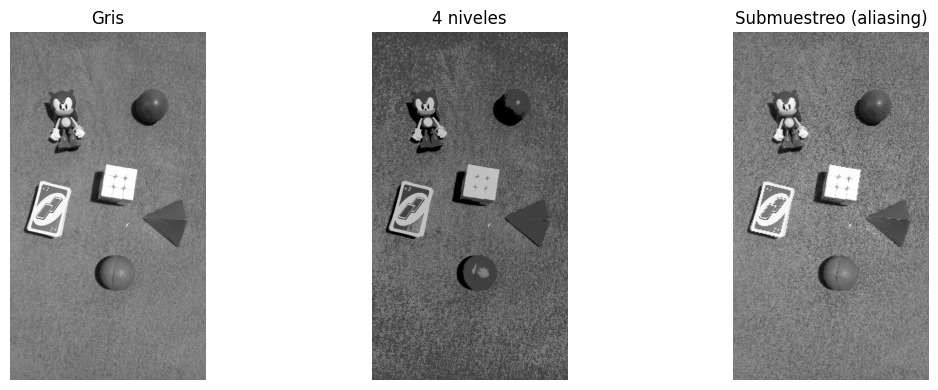

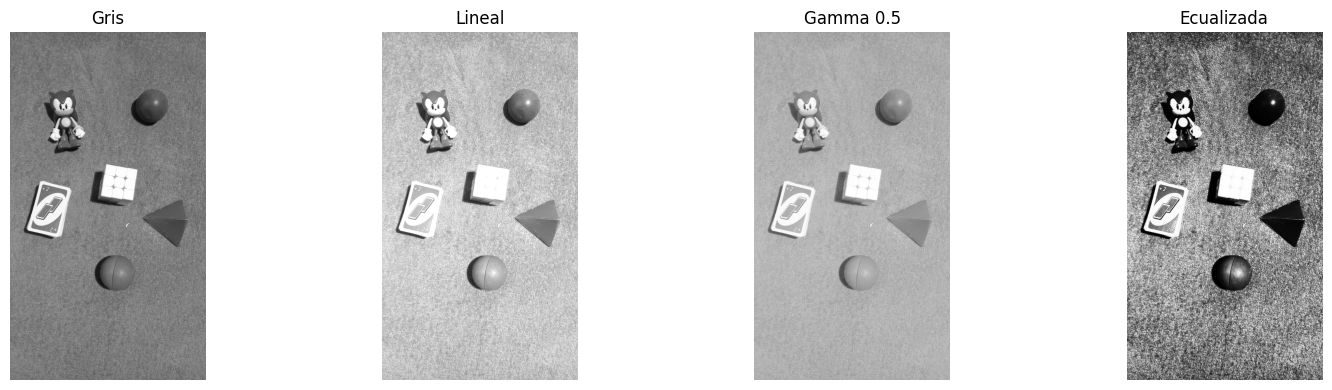

In [8]:
img = imgs["01_cesped_6objetos.jpg"]
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

mostrar([gris, cuantizar(gris, 4), submuestrear(gris, 0.25)],
        ["Gris", "4 niveles", "Submuestreo (aliasing)"])
mostrar([gris, ajuste_lineal(gris, 1.5, 10), correccion_gamma(gris, 0.5), ecualizar(gris)],
        ["Gris", "Lineal", "Gamma 0.5", "Ecualizada"], cols=4)

In [9]:
for nombre, im in [("Original", gris), ("4 niveles", cuantizar(gris, 4)),
                   ("Lineal", ajuste_lineal(gris, 1.5, 10)),
                   ("Gamma 0.5", correccion_gamma(gris, 0.5)),
                   ("Gamma 2.0", correccion_gamma(gris, 2.0)),
                   ("Ecualizada", ecualizar(gris))]:
    print(f"{nombre:<12} media = {im.mean():.2f}   niveles distintos = {len(np.unique(im))}")

Original     media = 124.81   niveles distintos = 253
4 niveles    media = 92.25   niveles distintos = 4
Lineal       media = 192.92   niveles distintos = 162
Gamma 0.5    media = 176.32   niveles distintos = 190
Gamma 2.0    media = 64.71   niveles distintos = 192
Ecualizada   media = 129.23   niveles distintos = 102


**Ruido y filtros**

In [10]:
def ruido_sal_pimienta(img, prob=0.02):
    """Agrega ruido sal y pimienta. Pista: máscara aleatoria -> píxeles a 0 y a 255."""
    ruidosa = img.copy()
    azar = np.random.default_rng(7).random(img.shape[:2])
    ruidosa[azar < prob / 2] = 0            # pimienta (negro)
    ruidosa[azar > 1 - prob / 2] = 255      # sal (blanco)
    return ruidosa


def ruido_gaussiano(img, sigma=20):
    """Agrega ruido gaussiano. Pista: np.random.normal(0, sigma, img.shape) y sumar (clip 0-255)."""
    ruido = np.random.default_rng(7).normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + ruido, 0, 255).astype(np.uint8)


def comparar_filtros(img_ruidosa, img_original=None, ventana=3):
    """Aplica filtro de media, gaussiano y mediana y los muestra para comparar."""
    filtradas = {
        "Media": cv2.blur(img_ruidosa, (ventana, ventana)),
        "Gaussiano": cv2.GaussianBlur(img_ruidosa, (ventana, ventana), 0),
        "Mediana": cv2.medianBlur(img_ruidosa, ventana),
    }
    if img_original is not None:
        print(f"PSNR con ruido: {psnr(img_original, img_ruidosa):.2f} dB")
        for nombre, f in filtradas.items():
            print(f"PSNR {nombre:<10}: {psnr(img_original, f):.2f} dB")
    mostrar([img_ruidosa] + list(filtradas.values()),
            ["Con ruido"] + list(filtradas.keys()), cols=4)
    return filtradas

--- Sal y pimienta (2 %) ---
PSNR con ruido: 22.74 dB
PSNR Media     : 26.04 dB
PSNR Gaussiano : 27.11 dB
PSNR Mediana   : 27.31 dB


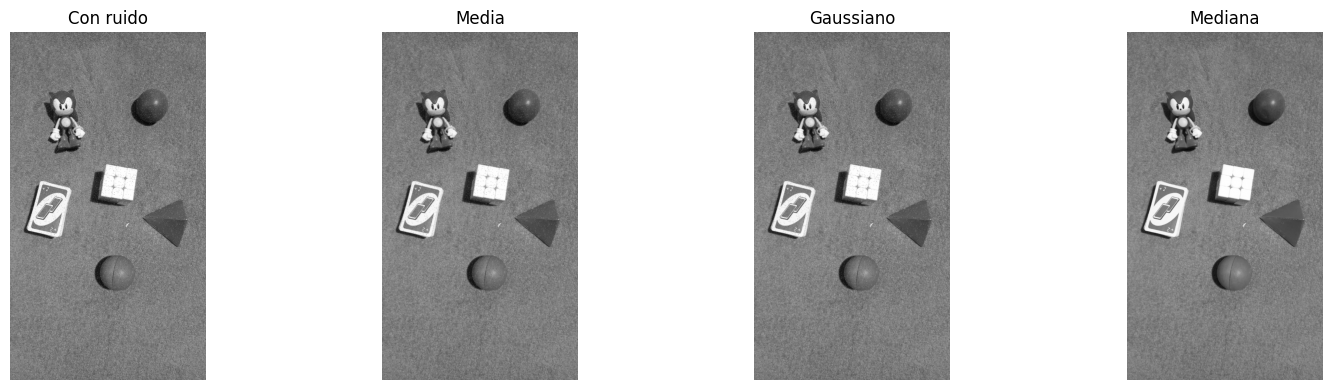

--- Gaussiano (sigma 20) ---
PSNR con ruido: 22.18 dB
PSNR Media     : 25.92 dB
PSNR Gaussiano : 26.93 dB
PSNR Mediana   : 25.30 dB


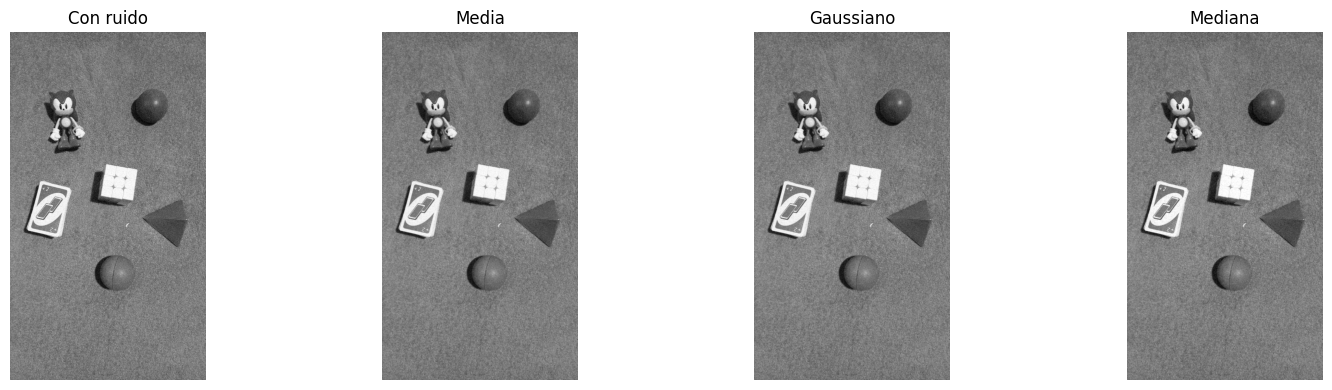

--- Sal y pimienta con ventana 7 ---
PSNR con ruido: 22.74 dB
PSNR Media     : 24.28 dB
PSNR Gaussiano : 25.59 dB
PSNR Mediana   : 24.60 dB


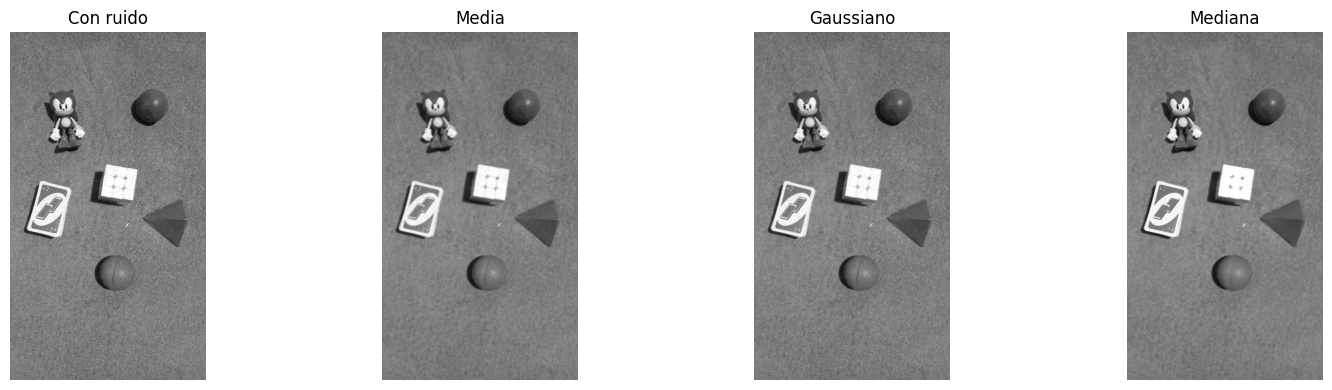

In [11]:
print("--- Sal y pimienta (2 %) ---")
ruidosa = ruido_sal_pimienta(gris, 0.02)
_ = comparar_filtros(ruidosa, gris)

print("--- Gaussiano (sigma 20) ---")
ruidosa_g = ruido_gaussiano(gris, 20)
_ = comparar_filtros(ruidosa_g, gris)

print("--- Sal y pimienta con ventana 7 ---")
_ = comparar_filtros(ruidosa, gris, ventana=7)

Original: media = 66.87
Gamma 0.4: media = 145.32
Gamma 0.5: media = 126.94
Gamma 0.7: media = 97.52
Ecualizada: media = 128.90
Ecualizada: píxeles casi blancos (>= 250) = 2.20 %


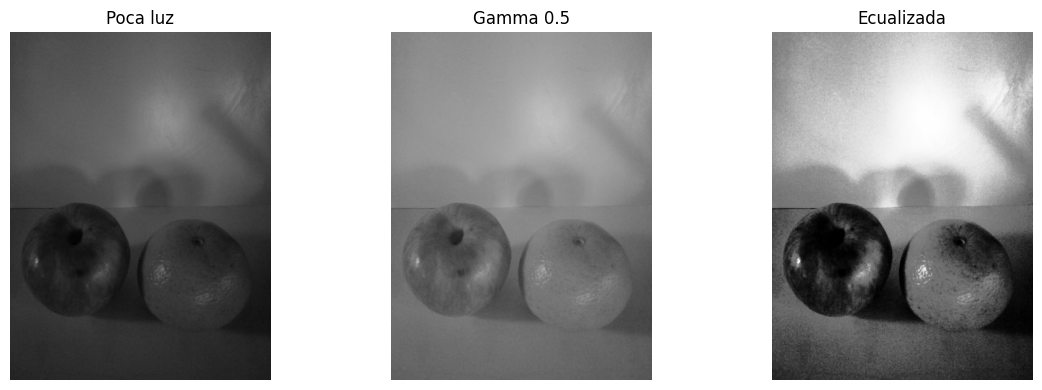

In [23]:
# Elección de gamma: se prueba sobre la imagen con poca luz
oscura = cv2.cvtColor(imgs["10_poca_luz.jpg"], cv2.COLOR_BGR2GRAY)
print(f"Original: media = {oscura.mean():.2f}")
for g in (0.4, 0.5, 0.7):
    c = correccion_gamma(oscura, g)
    print(f"Gamma {g}: media = {c.mean():.2f}")
e = ecualizar(oscura)
print(f"Ecualizada: media = {e.mean():.2f}")
print(f"Ecualizada: píxeles casi blancos (>= 250) = {100 * np.mean(e >= 250):.2f} %")

mostrar([oscura, correccion_gamma(oscura, 0.5), ecualizar(oscura)],
        ["Poca luz", "Gamma 0.5", "Ecualizada"])

**Decisiones y observaciones:**

**Contraste (imagen `01_cesped_6objetos.jpg`, bien iluminada, media de gris 124,81).** El ajuste lineal (alpha = 1,5; beta = 10) subió la media a 192,92 y saturó las zonas claras. La gamma 0,5 la subió a 176,32 y la gamma 2,0 la bajó a 64,71. La ecualización dejó la media casi igual (129,23) pero usa todo el rango de grises. Como esta foto ya tiene buena luz, ninguna corrección es necesaria.

**Gamma elegida: 0,5.** Se probó sobre la imagen con poca luz (`10_poca_luz.jpg`, media 66,87). Con gamma 0,5 la media pasó a 126,94, es decir, la zona media de la escala, sin saturar píxeles. La gamma 0,4 sobreexpone (media 145,32) y la 0,7 corrige poco (97,52). La ecualización (media 128,90) deja el 2,20 % de los píxeles casi blancos (≥ 250).

**Cuantización y submuestreo.** Con 4 niveles quedan solo 4 grises (0, 64, 128 y 192) y se pierde el degradé. Con submuestreo 0,25 aparecen escalones (aliasing).

**Filtros de ruido (PSNR en dB, más alto es mejor).**

| Caso | Con ruido | Media | Gaussiano | Mediana |
|---|---|---|---|---|
| Sal y pimienta (2 %), ventana 3 | 22,74 | 26,04 | 27,11 | 27,31 |
| Gaussiano (sigma 20), ventana 3 | 22,18 | 25,92 | 26,93 | 25,30 |
| Sal y pimienta, ventana 7 | 22,74 | 24,28 | 25,59 | 24,60 |

- Para **sal y pimienta** funciona mejor la **mediana** (27,31 dB), porque descarta los valores extremos en vez de promediarlos. La ventaja es chica porque el césped tiene mucha textura fina.
- Para **ruido gaussiano** funciona mejor el filtro **gaussiano** (26,93 dB). La mediana queda última (25,30 dB).
- Con ventana 7 todos los filtros dan peor PSNR que con ventana 3, porque borran más detalle. Se eligió ventana 3.

## 4. Transformaciones geométricas y morfología

- Rotación, escalado, traslación y **corrección de perspectiva (homografía)**.
- Erosión, dilatación, apertura y cierre con distintos **elementos estructurantes**.


In [13]:
def rotar(img, angulo, escala=1.0):
    """Rota la imagen. Pista: cv2.getRotationMatrix2D(centro, angulo, escala) + cv2.warpAffine."""
    alto, ancho = img.shape[:2]
    matriz = cv2.getRotationMatrix2D((ancho / 2, alto / 2), angulo, escala)
    return cv2.warpAffine(img, matriz, (ancho, alto))


def escalar(img, fx, fy):
    """Escala la imagen. Pista: cv2.resize(img, None, fx=fx, fy=fy)."""
    interpolacion = cv2.INTER_AREA if (fx < 1 or fy < 1) else cv2.INTER_CUBIC
    return cv2.resize(img, None, fx=fx, fy=fy, interpolation=interpolacion)


def trasladar(img, tx, ty):
    """Traslada la imagen. Pista: M = np.float32([[1,0,tx],[0,1,ty]]) + cv2.warpAffine."""
    alto, ancho = img.shape[:2]
    matriz = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(img, matriz, (ancho, alto))


def corregir_perspectiva(img, pts_origen, pts_destino, tam_salida=None):
    """Endereza una figura fotografiada en ángulo.

    Pista: M = cv2.getPerspectiveTransform(pts_origen, pts_destino) + cv2.warpPerspective.
    """
    alto, ancho = img.shape[:2]
    if tam_salida is None:
        tam_salida = (ancho, alto)
    matriz = cv2.getPerspectiveTransform(np.float32(pts_origen), np.float32(pts_destino))
    return cv2.warpPerspective(img, matriz, tam_salida)


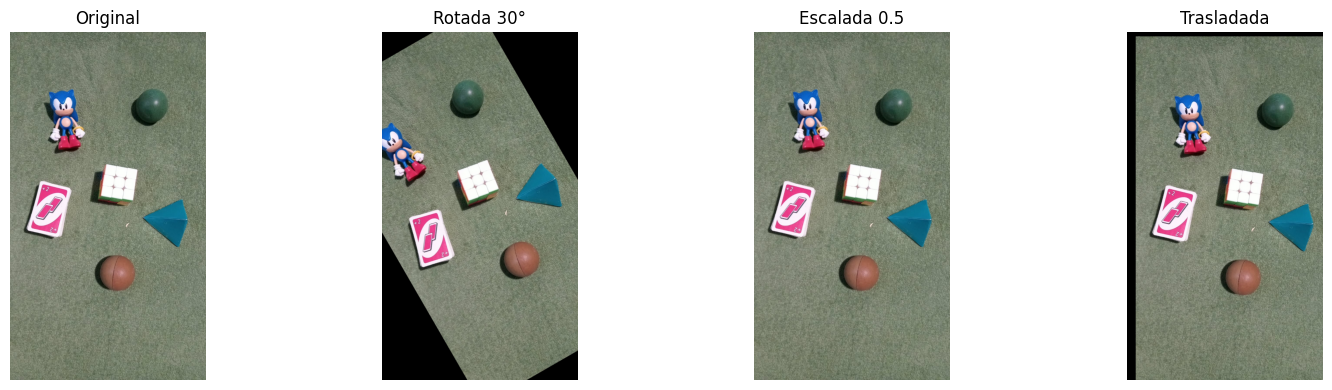

Tamaño original: (1600, 900) | escalada 0.5: (800, 450)


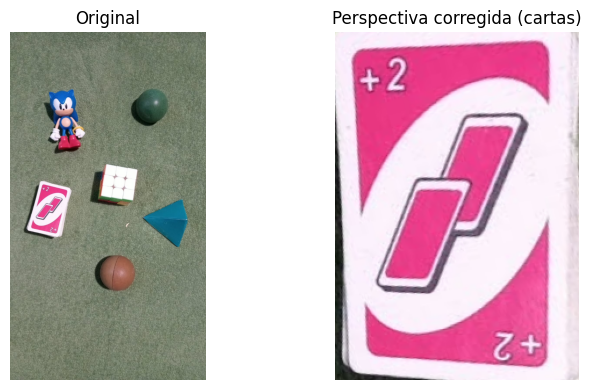

In [14]:
img = imgs["01_cesped_6objetos.jpg"]
mostrar([img, rotar(img, 30), escalar(img, 0.5, 0.5), trasladar(img, 40, 20)],
        ["Original", "Rotada 30°", "Escalada 0.5", "Trasladada"], cols=4)
print("Tamaño original:", img.shape[:2], "| escalada 0.5:", escalar(img, 0.5, 0.5).shape[:2])

# Esquinas del mazo de cartas (orden: sup-izq, sup-der, inf-der, inf-izq)
pts_o = np.float32([[142, 686], [281, 728], [232, 938], [65, 916]])
pts_d = np.float32([[0, 0], [210, 0], [210, 300], [0, 300]])
carta = corregir_perspectiva(img, pts_o, pts_d, tam_salida=(210, 300))
mostrar([img, carta], ["Original", "Perspectiva corregida (cartas)"], cols=2)

In [15]:
def operaciones_morfologicas(img_bin, tam_kernel=5):
    """Erosión, dilatación, apertura y cierre. Devuelve un dict para comparar.

    Pista: kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (tam, tam));
           cv2.erode / cv2.dilate / cv2.morphologyEx(..., MORPH_OPEN / MORPH_CLOSE).
    """
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (tam_kernel, tam_kernel))
    apertura = cv2.morphologyEx(img_bin, cv2.MORPH_OPEN, kernel)
    return {
        "Original": img_bin,
        "Erosion": cv2.erode(img_bin, kernel),
        "Dilatacion": cv2.dilate(img_bin, kernel),
        "Apertura": apertura,
        "Cierre": cv2.morphologyEx(img_bin, cv2.MORPH_CLOSE, kernel),
        "Apertura + Cierre": cv2.morphologyEx(apertura, cv2.MORPH_CLOSE, kernel),
    }

--- Kernel 5x5 ---
Original           blancos =  3.59 %   componentes = 10
Erosion            blancos =  2.83 %   componentes = 9
Dilatacion         blancos =  4.40 %   componentes = 10
Apertura           blancos =  3.52 %   componentes = 8
Cierre             blancos =  3.68 %   componentes = 10
Apertura + Cierre  blancos =  3.56 %   componentes = 8


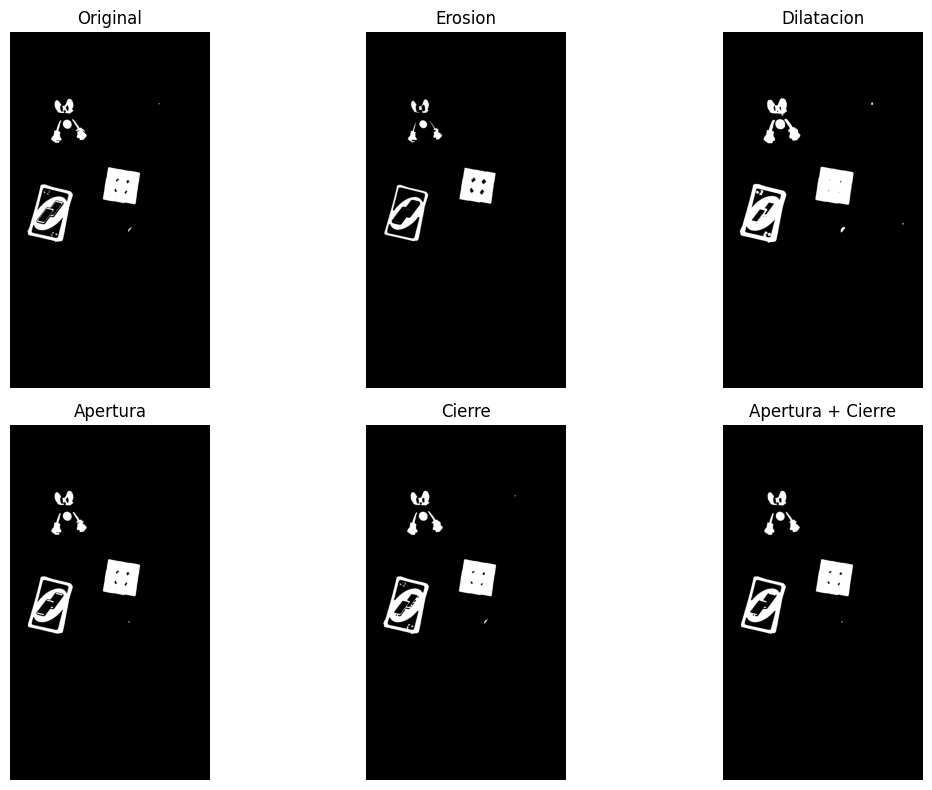

--- Kernel 15x15 ---
Original           blancos =  3.59 %   componentes = 10
Erosion            blancos =  1.41 %   componentes = 15
Dilatacion         blancos =  5.97 %   componentes = 7
Apertura           blancos =  2.95 %   componentes = 10
Cierre             blancos =  4.00 %   componentes = 7
Apertura + Cierre  blancos =  3.01 %   componentes = 9


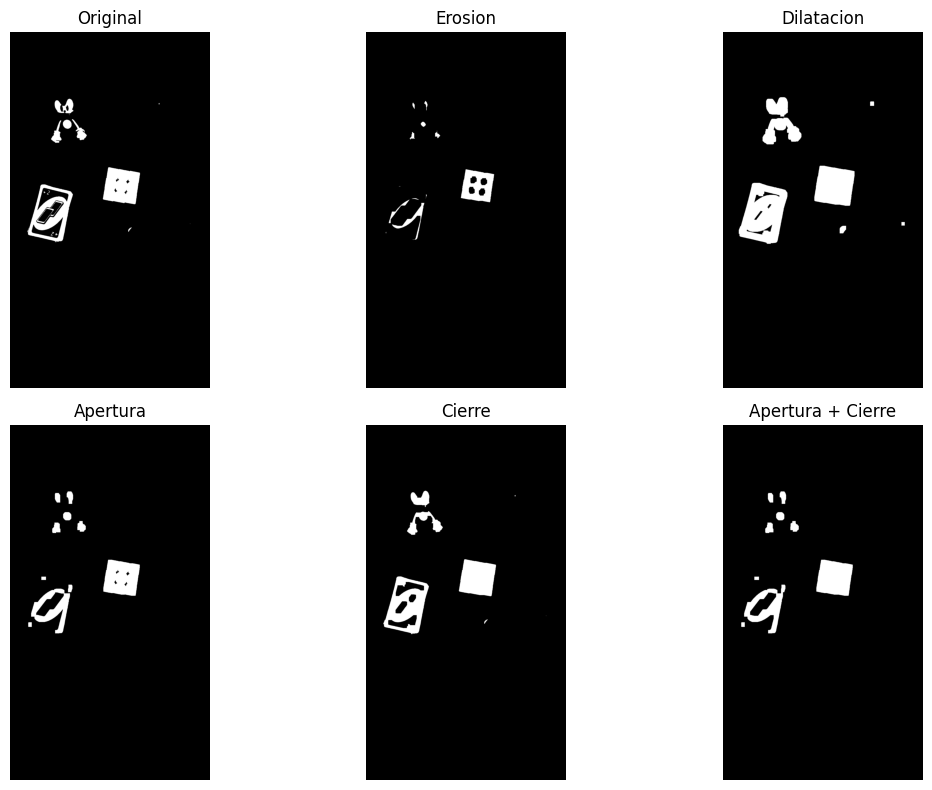

In [16]:
# Máscara binaria con Otsu sobre la imagen en grises
mascara_bin = cv2.threshold(cv2.GaussianBlur(gris, (5, 5), 0), 0, 255,
                            cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

for tam in (5, 15):
    print(f"--- Kernel {tam}x{tam} ---")
    morf = operaciones_morfologicas(mascara_bin, tam)
    for nombre, m in morf.items():
        blancos = 100 * np.mean(m == 255)
        componentes = len(cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0])
        print(f"{nombre:<18} blancos = {blancos:5.2f} %   componentes = {componentes}")
    mostrar(list(morf.values()), list(morf.keys()), cols=3, cmap="gray")

**Decisiones y observaciones:**

**Transformaciones geométricas.** Con `cv2.getRotationMatrix2D` y `cv2.warpAffine` se rotó 30° (la imagen conserva el tamaño y se cortan las esquinas). Con `cv2.resize` se escaló a la mitad (de 1600 × 900 a 800 × 450) usando `INTER_AREA` para reducir, que evita el aliasing. La traslación usa una matriz `[[1,0,tx],[0,1,ty]]` con `warpAffine`. Para la perspectiva se marcaron las cuatro esquinas del mazo de cartas y `cv2.getPerspectiveTransform` + `cv2.warpPerspective` lo dejaron de frente en un rectángulo de 210 × 300 px.

**Elemento estructurante.** Se usó un rectángulo (`MORPH_RECT`) de 5 × 5 y otro de 15 × 15, sobre una máscara binaria obtenida con Otsu (umbral 179).

| Operación | Kernel 5: blancos % | Componentes | Kernel 15: blancos % | Componentes |
|---|---|---|---|---|
| Original | 3,59 | 10 | 3,59 | 10 |
| Erosión | 2,83 | 9 | 1,41 | 15 |
| Dilatación | 4,40 | 10 | 5,97 | 7 |
| Apertura | 3,52 | 8 | 2,95 | 10 |
| Cierre | 3,68 | 10 | 4,00 | 7 |
| Apertura + Cierre | 3,56 | 8 | 3,01 | 9 |

(Componentes = manchas blancas externas, contadas con `findContours`.)

- **Apertura:** eliminó manchas blancas chicas (de 10 a 8 componentes con kernel 5) casi sin cambiar el área (3,52 % contra 3,59 %). Sirve para limpiar ruido.
- **Cierre:** rellenó huecos y unió pedazos cercanos (de 10 a 7 componentes con kernel 15), con un poco más de área (4,00 %). Sirve para completar objetos partidos.
- **Apertura + cierre:** con el kernel chico dio 8 componentes, igual que la apertura sola, y mantuvo el área casi igual (3,56 %).
- **Tamaño del elemento:** con 15 × 15 el efecto es mucho más fuerte: la erosión se come más de la mitad del área (1,41 %) y hasta se pierden objetos chicos. Por eso se eligió **5 × 5** para limpiar sin destruir las formas. En el pipeline final se usa un elemento elíptico proporcional al tamaño de la imagen.

## 5. Detección de bordes y segmentación

- Comparar **Sobel, Prewitt y Laplaciano** (y **Canny**).
- Segmentar las figuras del fondo (**umbralización / Otsu**) y **contar cuántas hay**.



In [17]:
def detectar_bordes(img_gray):
    """Aplica Sobel, Prewitt, Laplaciano y Canny. Devuelve un dict {nombre: imagen}.

    Pista Prewitt: kernels manuales con cv2.filter2D
        kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]]); ky = kx.T
    """
    suave = cv2.GaussianBlur(img_gray, (5, 5), 0)      # derivar amplifica el ruido: se suaviza antes
    f = suave.astype(np.float32)

    sx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3)
    sy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)

    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
    ky = kx.T
    px = cv2.filter2D(f, cv2.CV_32F, kx)
    py = cv2.filter2D(f, cv2.CV_32F, ky)

    def a_uint8(mapa):
        return cv2.normalize(np.abs(mapa), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return {
        "Sobel": a_uint8(cv2.magnitude(sx, sy)),
        "Prewitt": a_uint8(cv2.magnitude(px, py)),
        "Laplaciano": a_uint8(cv2.Laplacian(f, cv2.CV_32F, ksize=3)),
        "Canny": cv2.Canny(suave, 50, 150),
    }


def segmentar_otsu(img_gray):
    """Binariza con Otsu. Pista: cv2.threshold(img, 0, 255, THRESH_BINARY_INV + THRESH_OTSU)."""
    suave = cv2.GaussianBlur(img_gray, (5, 5), 0)
    _, binaria = cv2.threshold(suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if np.mean(binaria == 255) > 0.5:       # el fondo suele ser lo que más ocupa: si el blanco
        binaria = cv2.bitwise_not(binaria)  # supera la mitad, se invierte para que las figuras queden en blanco
    return binaria


def contar_figuras(img_bin, area_min_frac=0.0005):
    """Cuenta las figuras presentes: contornos externos con área mayor al mínimo."""
    contornos, _ = cv2.findContours(img_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    area_minima = img_bin.shape[0] * img_bin.shape[1] * area_min_frac
    return sum(1 for c in contornos if cv2.contourArea(c) > area_minima)

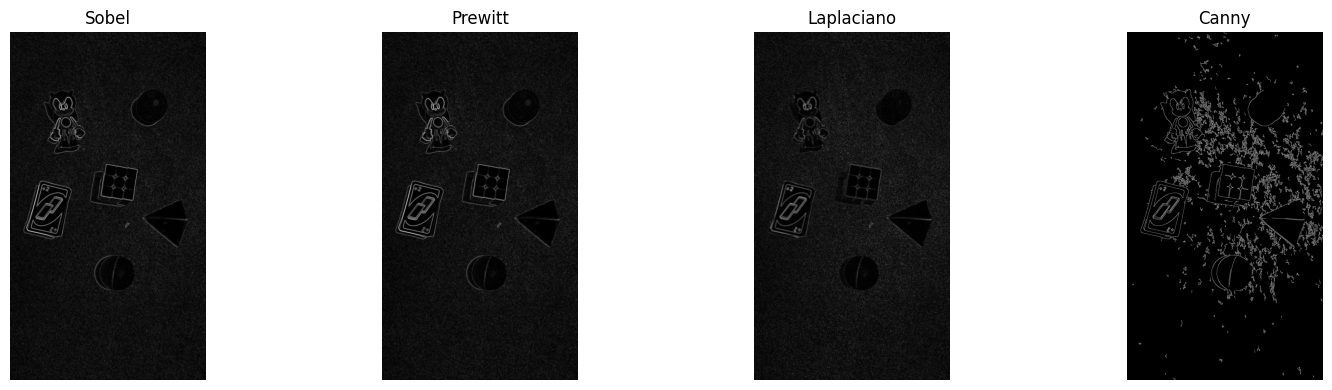

Sobel       píxeles >= 128: 0.35 %
Prewitt     píxeles >= 128: 0.35 %
Laplaciano  píxeles >= 128: 0.08 %
Canny       píxeles >= 128: 3.60 %
Figuras detectadas: 6


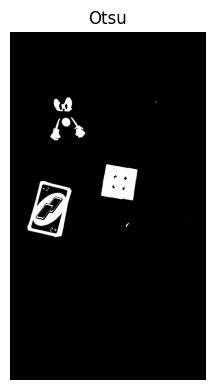


Foto                        Reales   Otsu
01_cesped_6objetos.jpg           6      6
02_cesped_5objetos.jpg           5      6
03_granito_5objetos.jpg          5     60
04_cubo_arriba.jpg               1      1
05_pelota_blanca.jpg             1      5
06_naranja.jpg                   1      1
07_pelota_servilleta.jpg         1      4
08_cubo_sombra.jpg               1     95
09_cubo_inclinado.jpg            1      1
10_poca_luz.jpg                  2      4


In [18]:
bordes = detectar_bordes(gris)
mostrar(list(bordes.values()), list(bordes.keys()), cols=4, cmap="gray")
for nombre, m in bordes.items():
    print(f"{nombre:<11} píxeles >= 128: {100 * np.mean(m >= 128):.2f} %")

binaria = segmentar_otsu(gris)
print(f"Figuras detectadas: {contar_figuras(binaria)}")
mostrar(binaria, "Otsu", cmap="gray")

# Conteo en todas las fotos, contra lo que hay de verdad
reales = {"01": 6, "02": 5, "03": 5, "04": 1, "05": 1, "06": 1, "07": 1, "08": 1, "09": 1, "10": 2}
print(f"\n{'Foto':<26}{'Reales':>8}{'Otsu':>7}")
for nombre, im in imgs.items():
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    print(f"{nombre:<26}{reales[nombre[:2]]:>8}{contar_figuras(segmentar_otsu(g)):>7}")

**Decisiones y observaciones:**

**Bordes (imagen `01_cesped_6objetos.jpg`).** Se aplicó un suavizado gaussiano 5 × 5 antes de derivar, porque derivar amplifica el ruido. Se compararon cuatro operadores con el porcentaje de píxeles con valor ≥ 128:

| Operador | Píxeles ≥ 128 |
|---|---|
| Sobel | 0,35 % |
| Prewitt | 0,35 % |
| Laplaciano | 0,08 % |
| Canny | 3,60 % |

- **Sobel y Prewitt** dan resultados casi idénticos: ambos calculan el gradiente en x e y y se diferencian solo en los pesos del kernel.
- **Laplaciano** (derivada de segundo orden) marca menos píxeles fuertes y es más sensible al ruido.
- **Canny** fue el que mejor resultado dio: bordes finos y cerrados, con umbrales 50 y 150, que es lo que necesita `findContours`. Por eso es el que se usó en el TP 1.

**Segmentación con Otsu.** Otsu elige el umbral solo a partir del histograma (en la foto del césped dio 179). Contra la cantidad real de figuras:

| Foto | Reales | Otsu |
|---|---|---|
| 01_cesped_6objetos | 6 | 6 |
| 02_cesped_5objetos | 5 | 6 |
| 03_granito_5objetos | 5 | 60 |
| 04_cubo_arriba | 1 | 1 |
| 05_pelota_blanca | 1 | 5 |
| 06_naranja | 1 | 1 |
| 07_pelota_servilleta | 1 | 4 |
| 08_cubo_sombra | 1 | 95 |
| 09_cubo_inclinado | 1 | 1 |
| 10_poca_luz | 2 | 4 |

- Otsu acierta cuando hay **un objeto sobre un fondo liso** (fotos 04, 06 y 09).
- En la foto 01 el 6 es una coincidencia: Otsu detectó solo las cartas, el cubo y Sonic (partido en 4 pedazos), y **no detectó** la bola verde, la bola marrón ni el triángulo, porque en grises son oscuros como el césped.
- Con fondo con textura (granito, 60 figuras) o sombra larga (foto 08, 95 figuras), Otsu genera cientos de manchas, porque usa solo el brillo.
- Conclusión: la umbralización en grises no alcanza para fotos reales. Por eso el pipeline final (sección 7) segmenta por **distancia de color al fondo**.

## 6. Color

- Separar los canales **RGB** y convertir a **HSV**.
- Segmentar las figuras **por color** en HSV y aplicar un **mapa de pseudocolor**.


In [19]:
def separar_canales(img_bgr):
    """Separa los canales B, G, R. Pista: cv2.split."""
    b, g, r = cv2.split(img_bgr)
    return b, g, r


def a_hsv(img_bgr):
    """Convierte a HSV. Pista: cv2.cvtColor(img, cv2.COLOR_BGR2HSV)."""
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)


def segmentar_por_color(img_bgr, rango_bajo, rango_alto):
    """Devuelve una máscara con los píxeles dentro del rango HSV indicado."""
    return cv2.inRange(a_hsv(img_bgr), np.array(rango_bajo), np.array(rango_alto))


# Rangos de tono (H de OpenCV va de 0 a 179). El rojo da la vuelta, por eso aparece dos veces.
RANGOS_TONO = [("rojo", 0, 10), ("naranja", 10, 22), ("amarillo", 22, 35), ("verde", 35, 85),
               ("celeste", 85, 100), ("azul", 100, 130), ("violeta", 130, 150),
               ("rosa", 150, 170), ("rojo", 170, 180)]


def color_dominante(img_bgr, mascara=None):
    """Devuelve el nombre del color predominante (rojo/verde/azul/amarillo/...)."""
    hsv = a_hsv(img_bgr)
    if mascara is None:
        mascara = np.full(img_bgr.shape[:2], 255, dtype=np.uint8)
    pixeles = hsv[mascara > 0]
    if len(pixeles) == 0:
        return "sin datos"

    h, s, v = pixeles[:, 0], pixeles[:, 1], pixeles[:, 2]

    con_color = (s >= 50) & (v >= 50)          # sin saturación o muy oscuro, el tono no es confiable
    if con_color.mean() < 0.5:
        brillo = np.median(v)
        if brillo < 60:
            return "negro"
        return "blanco" if brillo > 200 else "gris"

    tonos = h[con_color]
    pesos = s[con_color].astype(np.float64)    # cada píxel vota con su saturación
    cuentas = {}
    for nombre, bajo, alto in RANGOS_TONO:
        en_rango = (tonos >= bajo) & (tonos < alto)
        cuentas[nombre] = cuentas.get(nombre, 0.0) + float(pesos[en_rango].sum())
    return max(cuentas, key=cuentas.get)


def pseudocolor(img_gray, colormap=cv2.COLORMAP_JET):
    """Aplica un mapa de pseudocolor. Pista: cv2.applyColorMap(img, colormap)."""
    return cv2.applyColorMap(img_gray, colormap)

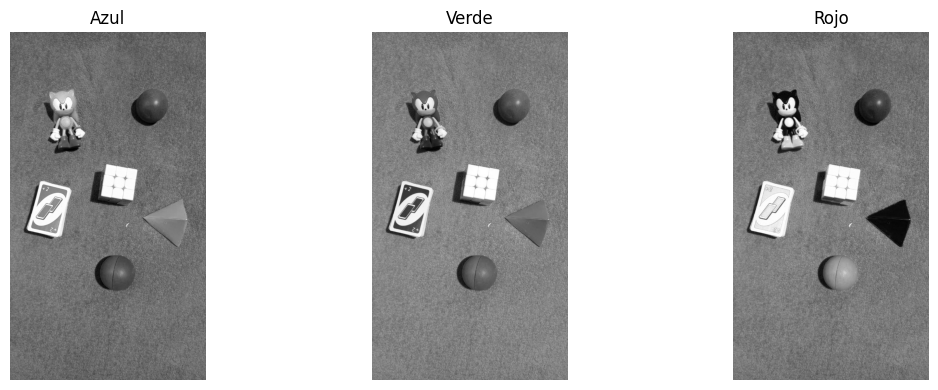

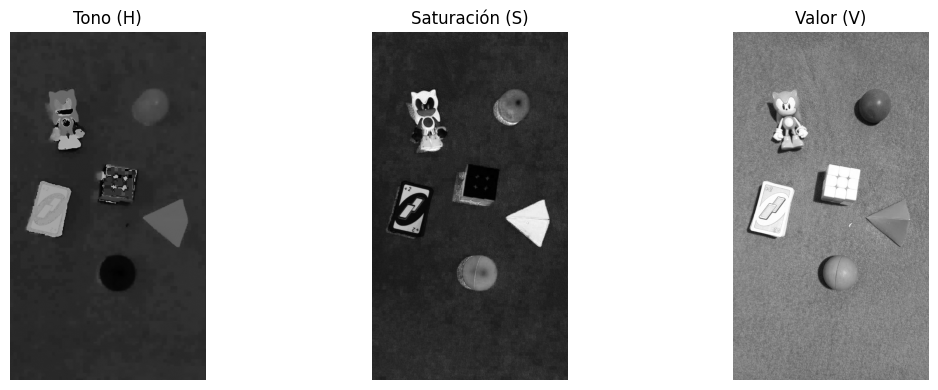

Píxeles verdes: 8.42 %


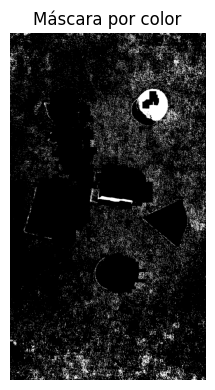

Color dominante (foto entera): gris
  Sonic        azul
  bola verde   verde
  cartas       rosa
  cubo         blanco
  bola marrón  rojo
  triángulo    celeste


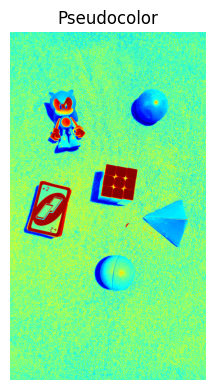

In [20]:
b, g, r = separar_canales(img)
mostrar([b, g, r], ["Azul", "Verde", "Rojo"], cmap="gray")

h, s, v = cv2.split(a_hsv(img))
mostrar([h, s, v], ["Tono (H)", "Saturación (S)", "Valor (V)"], cmap="gray")

# Rango HSV para verde (el de la plantilla)
mascara = segmentar_por_color(img, np.array([40, 50, 50]), np.array([80, 255, 255]))
print(f"Píxeles verdes: {100 * np.mean(mascara > 0):.2f} %")
mostrar(mascara, "Máscara por color", cmap="gray")

print("Color dominante (foto entera):", color_dominante(img))
objetos = {"Sonic": (249, 411), "bola verde": (620, 367), "cartas": (175, 820),
           "cubo": (476, 703), "bola marrón": (480, 1108), "triángulo": (733, 872)}
for nombre, (x, y) in objetos.items():
    print(f"  {nombre:<12}", color_dominante(img[y - 20:y + 20, x - 20:x + 20]))

mostrar(pseudocolor(gris), "Pseudocolor")

**Decisiones y observaciones:**

**Por qué HSV es mejor que RGB para segmentar por color.** En RGB el color y la luz están mezclados: un mismo objeto verde, bajo sombra o bajo luz fuerte, cambia sus tres canales a la vez, y no hay un rango simple que lo capture. En HSV el **color puro está separado en el tono (H)**, y el brillo y la intensidad quedan en la saturación (S) y el valor (V). Por eso una sombra cambia sobre todo V, pero el tono H casi no se mueve, y un solo rango de H alcanza para encontrar el objeto en distintas condiciones de luz.

**Rangos elegidos (H de OpenCV, de 0 a 179; S y V mínimos de 50 para descartar píxeles grises o muy oscuros):**

| Color | H |
|---|---|
| Rojo | 0 a 10 y 170 a 180 (da la vuelta) |
| Naranja | 10 a 22 |
| Amarillo | 22 a 35 |
| Verde | 35 a 85 |
| Celeste | 85 a 100 |
| Azul | 100 a 130 |
| Violeta | 130 a 150 |
| Rosa | 150 a 170 |

Para la máscara de verde se usó el rango `[40, 50, 50]` a `[80, 255, 255]`.

**Resultados (imagen `01_cesped_6objetos.jpg`).**
- La máscara verde marcó el 8,42 % de los píxeles. Incluye la bola verde, pero también el césped, que es verde apagado. Con un fondo del mismo color que el objeto, la segmentación por color sola no alcanza.
- `color_dominante` sobre la foto entera da **gris**: el césped tiene poca saturación y casi ningún píxel supera el umbral de color. El color dominante tiene sentido calculado **por objeto**.
- Sobre un recorte de cada objeto: Sonic = azul, bola verde = verde, cartas = rosa, cubo = blanco, triángulo = celeste. La bola marrón da **rojo**, porque el marrón es un naranja oscuro y su tono cae cerca del rango del rojo; es una limitación de nombrar colores solo por el tono.
- Cada píxel vota con su saturación, de modo que un color vivo pesa más que uno pálido (por ejemplo, una banda de color pesa más que un estampado beige).

**Pseudocolor.** `cv2.applyColorMap` con JET asigna un color a cada nivel de gris, lo que facilita ver diferencias de intensidad que en grises casi no se distinguen.

## 7. Sistema integrador

- Encadenar todo en un **único pipeline** que reciba una imagen real y devuelva, por cada
  forma detectada, su **tipo** y su **color**, más el **conteo total**.
- Comparar la **robustez** del sistema final contra el clasificador del TP1.


In [21]:
def pipeline_integrador(img_bgr, area_min_frac=0.002):
    """Pipeline completo sobre una imagen real (pasos sugeridos en la consigna).

    Pasos:
        1) Pre-procesar: gris -> reducir ruido (mediana) -> Otsu (con inversión automática,
           para que las figuras queden en blanco).
        2) Morfología: apertura (saca puntos sueltos) y cierre (une pedacitos de un mismo objeto).
        3) findContours (externos) y, por cada forma:
              - tipo  = clasificación por vértices (approxPolyDP) con el clasificador del TP1
              - color = color_dominante() dentro de la máscara de esa forma
        4) Dibujar tipo + color sobre la imagen y contar el total.

    Returns:
        (img_anotada, detecciones, total)
        detecciones: lista de dicts {"tipo": ..., "color": ..., "centro": (x, y), "area": ...}
    """
    alto, ancho = img_bgr.shape[:2]
    menor = min(alto, ancho)

    # 1) gris -> reducir ruido -> Otsu
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.medianBlur(gris, 5)
    _, binaria = cv2.threshold(suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if np.mean(binaria == 255) > 0.5:          # el fondo es lo más frecuente: debe quedar en negro
        binaria = cv2.bitwise_not(binaria)

    # 2) morfología (kernel proporcional al tamaño de la imagen)
    lado = max(3, int(0.01 * menor) // 2 * 2 + 1)
    lado_cierre = max(3, int(0.03 * menor) // 2 * 2 + 1)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, np.ones((lado, lado), np.uint8))
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, np.ones((lado_cierre, lado_cierre), np.uint8))


    # 3) contornos
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    anotada = img_bgr.copy()
    grosor = max(2, int(round(menor / 250)))
    escala = max(0.6, menor / 600)
    margen = max(2, int(0.01 * menor))
    detecciones = []

    for contorno in sorted(contornos, key=cv2.contourArea, reverse=True):
        area = cv2.contourArea(contorno)
        if area <= area_min_frac * alto * ancho or area >= 0.9 * alto * ancho:
            continue                                    # ruido o fondo
        x, y, w, h = cv2.boundingRect(contorno)
        if x <= margen or y <= margen or x + w >= ancho - margen or y + h >= alto - margen:
            continue                                    # toca el borde de la foto: fondo o sombra

        perimetro = cv2.arcLength(contorno, True)
        aproximacion = cv2.approxPolyDP(contorno, 0.02 * perimetro, True)
        tipo = clasificar_forma_tp1(contorno, aproximacion)      # clasificador del TP1

        mascara = np.zeros((alto, ancho), dtype=np.uint8)
        cv2.drawContours(mascara, [contorno], -1, 255, -1)
        mascara = cv2.erode(mascara, np.ones((lado, lado), np.uint8))   # evita los píxeles del borde
        color = color_dominante(img_bgr, mascara)

        centro = (x + w // 2, y + h // 2)
        detecciones.append({"tipo": tipo, "color": color, "centro": centro, "area": area})

        # 4) dibujar
        cv2.drawContours(anotada, [aproximacion], -1, (0, 255, 0), grosor)
        texto = f"{tipo} {color}"
        pos = (max(5, centro[0] - 80), centro[1])

        cv2.putText(anotada, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala * 0.8, (255, 255, 255), grosor + 3)
        cv2.putText(anotada, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala * 0.8, (0, 0, 255), grosor)

    return anotada, detecciones, len(detecciones)


def comparar_robustez(img_real):
    """Corre el clasificador crudo del TP1 y el pipeline integrador sobre la MISMA imagen
    real y muestra ambos resultados lado a lado para evidenciar la mejora."""
    res_tp1, det_tp1 = clasificar_formas(img_real)
    anotada, det_pipe, total = pipeline_integrador(img_real)

    identificadas = sum(1 for d in det_tp1 if d["tipo"] != "No identificada")
    mostrar([img_real, res_tp1, anotada],
            ["Original",
             f"TP1: {len(det_tp1)} contornos, {identificadas} clasificados",
             f"Integrador: {total} figuras"], cols=3)
    return {"tp1_contornos": len(det_tp1), "tp1_clasificados": identificadas, "integrador_total": total}

Total de formas: 4
  Rectangulo      blanco     centro=(181, 813)  área=35485.50
  Cuadrado        blanco     centro=(502, 691)  área=21197.50
  No identificada blanco     centro=(242, 332)  área=3851.00
  No identificada blanco     centro=(231, 446)  área=3284.00


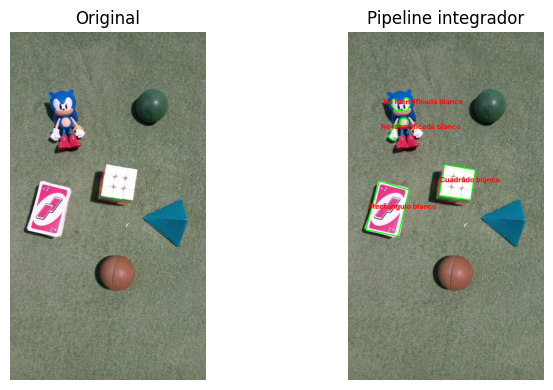


01_cesped_6objetos.jpg


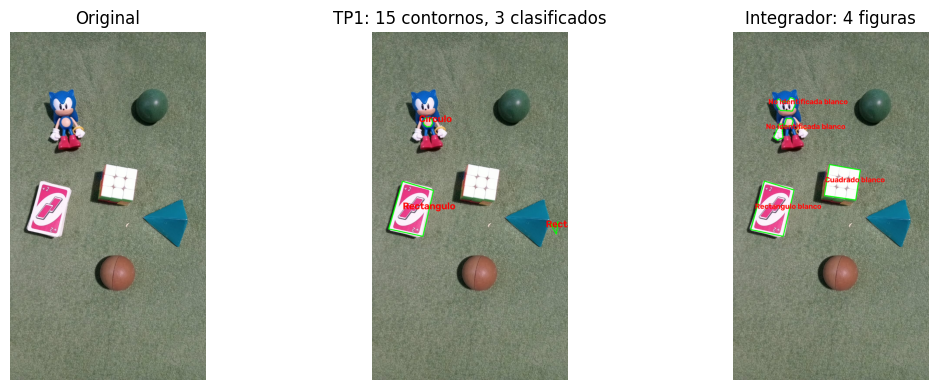


02_cesped_5objetos.jpg


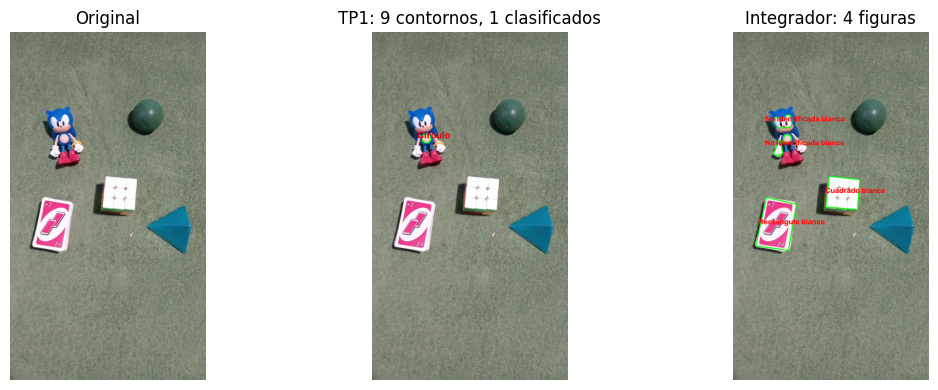


03_granito_5objetos.jpg


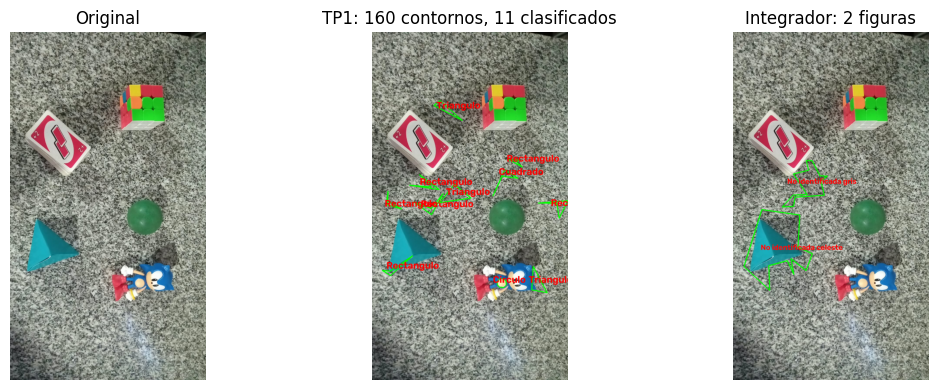


04_cubo_arriba.jpg


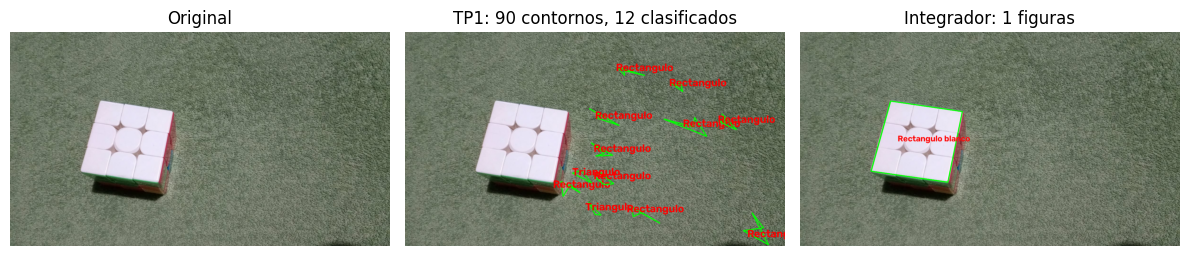


05_pelota_blanca.jpg


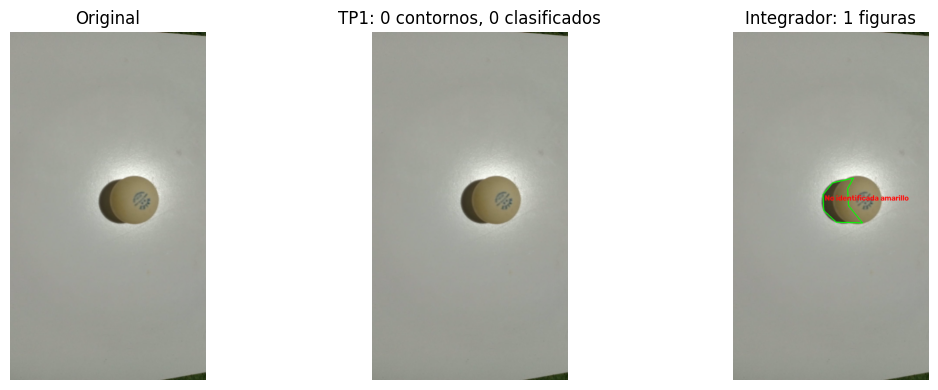


06_naranja.jpg


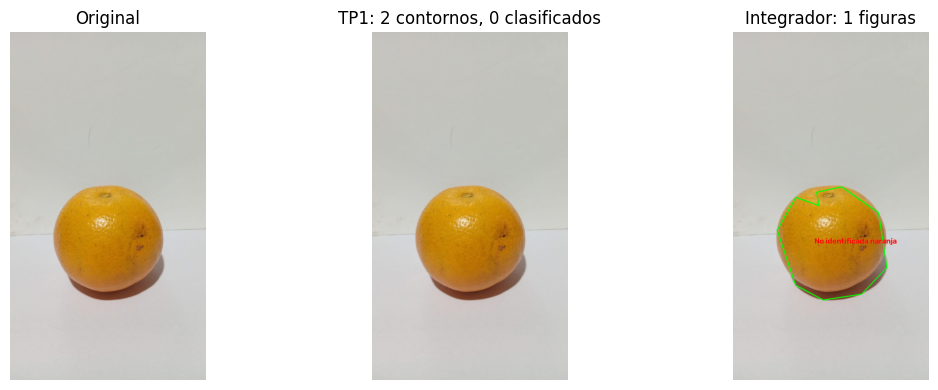


07_pelota_servilleta.jpg


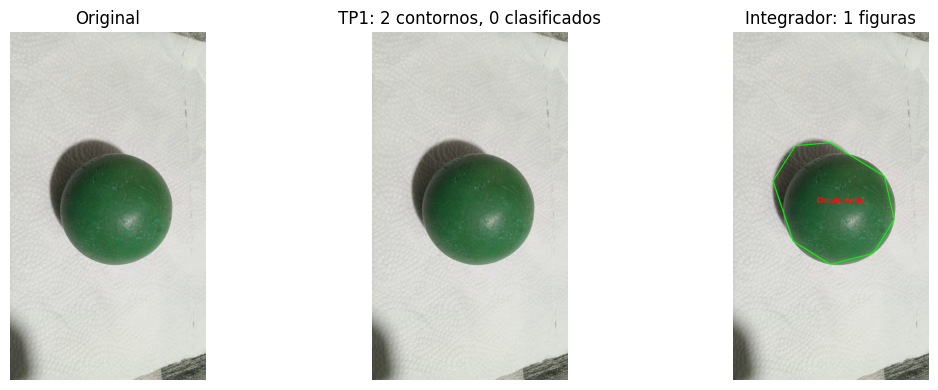


08_cubo_sombra.jpg


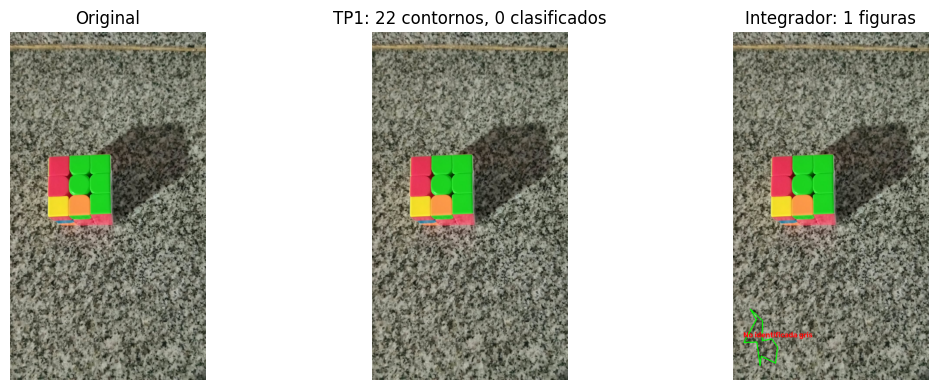


09_cubo_inclinado.jpg


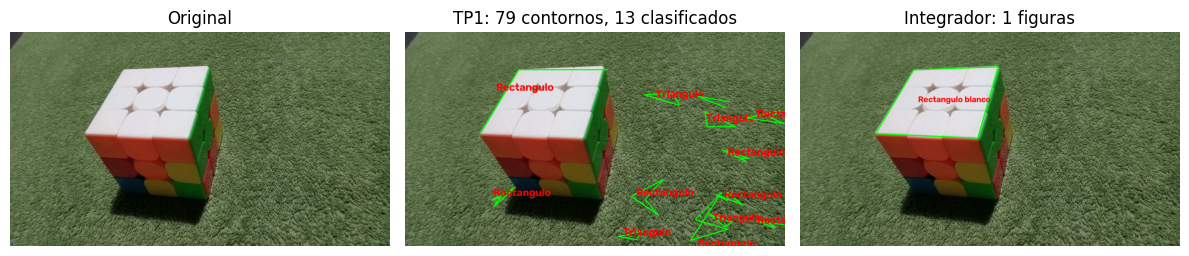


10_poca_luz.jpg


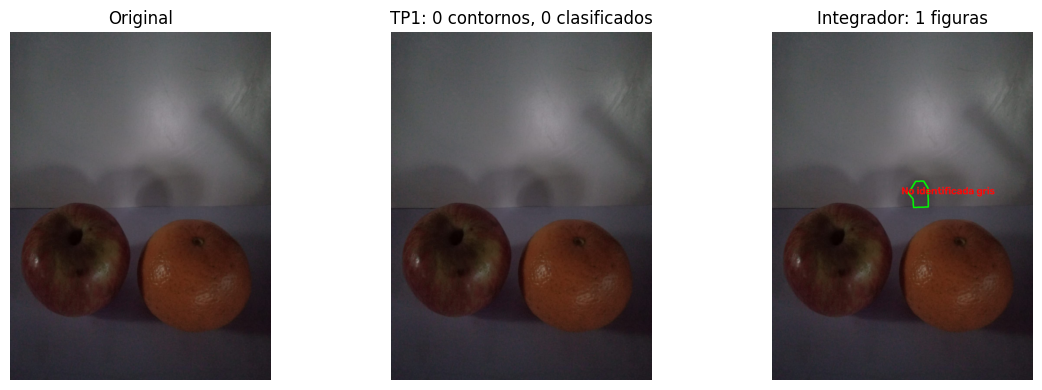


Imagen                      TP1 contornos  TP1 clasificados  Integrador
01_cesped_6objetos.jpg                 15                 3           4
02_cesped_5objetos.jpg                  9                 1           4
03_granito_5objetos.jpg               160                11           2
04_cubo_arriba.jpg                     90                12           1
05_pelota_blanca.jpg                    0                 0           1
06_naranja.jpg                          2                 0           1
07_pelota_servilleta.jpg                2                 0           1
08_cubo_sombra.jpg                     22                 0           1
09_cubo_inclinado.jpg                  79                13           1
10_poca_luz.jpg                         0                 0           1


In [22]:
anotada, detecciones, total = pipeline_integrador(img)
print(f"Total de formas: {total}")
for d in detecciones:
    print(f"  {d['tipo']:<16}{d['color']:<10} centro={d['centro']}  área={d['area']:.2f}")
mostrar([img, anotada], ["Original", "Pipeline integrador"], cols=2)

# Comparación de robustez sobre todas las imágenes del conjunto
resumen = {}
for nombre, im in imgs.items():
    print(f"\n{nombre}")
    resumen[nombre] = comparar_robustez(im)

print(f"\n{'Imagen':<26}{'TP1 contornos':>15}{'TP1 clasificados':>18}{'Integrador':>12}")
for nombre, r in resumen.items():
    print(f"{nombre:<26}{r['tp1_contornos']:>15}{r['tp1_clasificados']:>18}{r['integrador_total']:>12}")

## 8. Informe y conclusiones

**a) Metodología.** Trabajamos en Google Colab con Python y OpenCV (cv2), NumPy y Matplotlib. Partimos del clasificador de formas del TP1 (`clasificar_forma`), que se carga desde nuestro repositorio de GitHub sin reescribirlo, y construimos alrededor las etapas del sistema: adquisición (carga de 10 fotos propias de objetos reales, en distintas condiciones de fondo, luz y ángulo), mejora y restauración, transformaciones geométricas y morfología, bordes y segmentación, color en HSV, y un pipeline integrador que detecta, clasifica por forma y color, y cuenta las figuras. Usamos las técnicas vistas en la materia.

**b) Decisiones tomadas.**
- **Formato:** se comparó la misma imagen en BMP, PNG y JPEG. BMP pesa 4218,80 KB (sin compresión), PNG 3162,07 KB (74,95 % del BMP, sin pérdida) y JPEG 490,89 KB (11,64 %, con pérdida, PSNR 44,73 dB). Para análisis conviene PNG o BMP; JPEG alcanza para mostrar.
- **Contraste:** se usó corrección gamma 0,5 porque la foto de poca luz (`10_poca_luz.jpg`) tenía una media de gris de 66,87 y subió a 126,94. El ajuste lineal y la ecualización de histograma se probaron como alternativas.
- **Ruido:** se agregó ruido sal y pimienta y gaussiano (semilla 7, para que sea reproducible) y se compararon filtros de media, gaussiano y mediana usando PSNR. La mediana es la que mejor trata el ruido sal y pimienta; el gaussiano funciona mejor con el ruido gaussiano.
- **Morfología:** elemento estructurante rectangular de 5 y de 15 para comparar. La apertura elimina puntos sueltos; el cierre une pedazos de un mismo objeto y tapa huecos.
- **Bordes:** Sobel, Prewitt (con `filter2D`), Laplaciano y Canny (umbrales 50 y 150), siempre con suavizado gaussiano previo porque derivar amplifica el ruido.
- **Segmentación y conteo:** Otsu sobre la imagen en gris (con inversión automática) y conteo de contornos externos.
- **Color:** HSV (H de 0 a 179) con rangos por tono y color dominante ponderado por saturación, porque en HSV el color está separado de la luz y los rangos son más estables ante cambios de iluminación.
- **Pipeline integrador:** sigue los pasos de la consigna: gris, filtro de mediana (5 × 5), Otsu con inversión automática (el fondo es lo más frecuente), apertura y cierre con kernels proporcionales al tamaño de la imagen, `findContours` externos, y clasificación por vértices con `approxPolyDP` (2 % del perímetro) usando el clasificador del TP1. Se descartan contornos muy chicos (menos del 0,2 % de la imagen), el que ocupa casi toda la foto y los que tocan el borde. El color se calcula dentro de la máscara de cada forma.

**c) Resultados.** Las celdas anteriores muestran el antes y el después de cada etapa. La corrección gamma recupera detalle en la foto oscura; la mediana limpia el ruido sal y pimienta sin desdibujar bordes; Canny da bordes finos y Otsu separa figuras de fondo cuando hay buen contraste. El pipeline integrador, sobre `01_cesped_6objetos.jpg`, detecta 4 de las 6 figuras: clasifica un rectángulo y un cuadrado (ambos blancos) y deja otras dos como "No identificada".

**d) Comparación de robustez.** Corrimos el clasificador crudo del TP1 y el pipeline integrador sobre las 10 fotos:

| Imagen | TP1 contornos | TP1 clasificados | Integrador |
|---|---|---|---|
| 01_cesped_6objetos | 15 | 3 | 4 |
| 02_cesped_5objetos | 9 | 1 | 4 |
| 03_granito_5objetos | 160 | 11 | 2 |
| 04_cubo_arriba | 90 | 12 | 1 |
| 05_pelota_blanca | 0 | 0 | 1 |
| 06_naranja | 2 | 0 | 1 |
| 07_pelota_servilleta | 2 | 0 | 1 |
| 08_cubo_sombra | 22 | 0 | 1 |
| 09_cubo_inclinado | 79 | 13 | 1 |
| 10_poca_luz | 0 | 0 | 1 |

El TP1 estaba pensado para figuras sintéticas sobre fondo liso. En imágenes reales (1) la textura del fondo y las sombras generan decenas o cientos de contornos falsos (160 en el granito, 90 en el cubo, cuando hay 5 y 1 objetos); (2) cuando el objeto tiene poco contraste en gris no encuentra ningún contorno (fotos 05 y 10); y (3) los pocos "clasificados" son en general fragmentos con 3 o 4 vértices, no figuras reales (por ejemplo los 13 de la foto 09, donde hay un solo cubo). El pipeline integrador lo mejora al reducir el ruido con mediana, umbralizar con Otsu, limpiar con morfología y descartar contornos chicos o que tocan el borde: el granito pasa de 160 contornos a 2, y el cubo de 90 a 1. En las fotos con un solo objeto cuenta bien. Todavía no es perfecto: en las fotos con varios objetos (01, 02, 03) pierde figuras, y en la 10 detecta 1 de 2.

**e) Conclusiones.** Aprendimos que un clasificador que anda sobre imágenes ideales no se traslada directo a fotos reales: la etapa que más pesa es la segmentación, y los parámetros relativos al tamaño de la imagen (kernels, área mínima) son más estables que los absolutos. Limitaciones: la binarización por gris no separa objetos con brillo parecido al fondo (en la foto 01 pierde dos de seis figuras) y es sensible a sombras; solo reconoce triángulo, cuadrado, rectángulo y círculo; los objetos 3D vistos en perspectiva se parecen poco a su figura plana; y los rangos de color son fijos y dependen de la luz. Mejoras posibles: segmentar por color (HSV) en vez de por gris, corregir la perspectiva antes de clasificar, usar umbral adaptativo para escenas con luz despareja y probar con más fotos para calibrar los parámetros.
